# ECM-402: AI for Signal Processing — Lab 3

## Feedforward Neural Networks and Automatic Modulation Classification

This notebook contains the complete Lab 3 implementation, organized problem-by-problem for a clean Git repository.

### Contents

- **Part A — Neural Network from Scratch (NumPy)**
  - Problem 1: Spiral dataset preparation
  - Problem 2: Dense layer, ReLU, softmax + cross-entropy, optimizers, and gradient checking
  - Problem 3: Training and optimizer comparison
  - Problem 4: Network-capacity comparison
- **Part B — MLP for Automatic Modulation Classification (PyTorch)**
  - Problem 5: Signal visualization and feature engineering
  - Problem 6: MLP implementation and training
  - Problem 7: Optimizer and learning-rate comparison
  - Problem 8: Performance versus SNR and error analysis

> **Code organization:** Code cells contain only the implementation required for the corresponding problem or its direct downstream dependencies. Outputs and execution counts from the reference notebook have been removed so the repository starts cleanly.

The experiments are CPU-compatible and use synthetic datasets generated directly in the notebook.


# Part A — Neural Network from Scratch (NumPy)

## A0. Setup

Imports required by Part A.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True

## Problem 1 — Dataset Preparation

### 1(a) Generate and visualize the spiral dataset at two noise levels

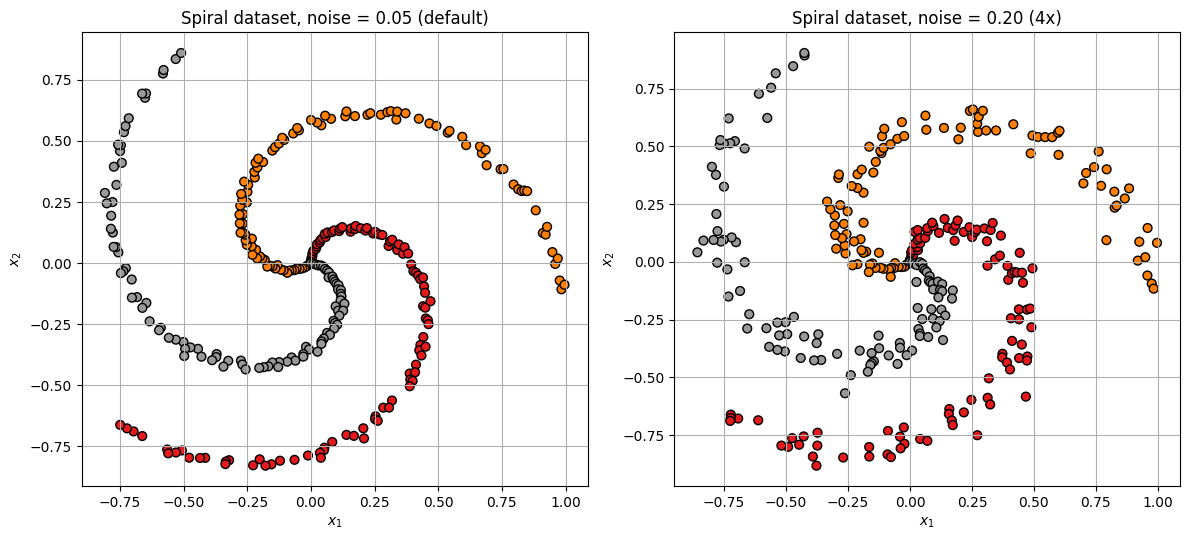

X shape: (300, 2), y shape: (300,), classes: [0 1 2]


In [2]:
def generate_data(N=100, K=3, seed=42, noise=0.05):
    """3-class spiral dataset. `noise` is the std-dev of the angular perturbation."""
    np.random.seed(seed)
    D = 2
    X = np.zeros((N * K, D))
    y = np.zeros(N * K, dtype="uint8")
    for j in range(K):
        ix = range(N * j, N * (j + 1))
        r = np.linspace(0.0, 1, N)
        theta = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * noise
        X[ix] = np.c_[r * np.sin(theta), r * np.cos(theta)]
        y[ix] = j
    return X, y


X, y = generate_data(N=100, K=3, seed=42, noise=0.05)
X_noisy, y_noisy = generate_data(N=100, K=3, seed=42, noise=0.20)  # 4x the noise

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (Xp, yp, title) in zip(axes, [(X, y, "noise = 0.05 (default)"),
                                       (X_noisy, y_noisy, "noise = 0.20 (4x)")]):
    ax.scatter(Xp[:, 0], Xp[:, 1], c=yp, s=40, cmap=plt.cm.Set1, edgecolors="k")
    ax.set_title(f"Spiral dataset, {title}")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
fig.tight_layout(); plt.show()

print(f"X shape: {X.shape}, y shape: {y.shape}, classes: {np.unique(y)}")

### 1(b) Why a linear model cannot solve this

A linear classifier such as logistic regression or a linear SVM can only produce straight-line decision boundaries in the input plane. The three spiral classes are nonlinearly intertwined, so a nonlinear hidden layer is required.

## Problem 2 — Neural Network Implementation from Scratch

The network is implemented using NumPy only. The required components are a dense layer, ReLU activation, fused softmax + cross-entropy loss, optimizers, a small network container, and a numerical gradient check.

### 2(a) `DenseLayer`

In [3]:
class DenseLayer:
    """Fully connected layer: z = X @ W + b."""

    def __init__(self, n_in, n_out, seed=None):
        rng = np.random.default_rng(seed)
        # He initialization: N(0, 2/n_in). See discussion below on why scale matters.
        self.W = rng.normal(0, np.sqrt(2.0 / n_in), size=(n_in, n_out))
        self.b = np.zeros((1, n_out))
        self.X = None
        self.dW = None
        self.db = None

    def forward(self, X):
        self.X = X                      # cached for the backward pass
        return X @ self.W + self.b

    def backward(self, dZ):
        """dZ = dL/dz (same shape as this layer's output). Returns dL/dX."""
        self.dW = self.X.T @ dZ
        self.db = np.sum(dZ, axis=0, keepdims=True)
        return dZ @ self.W.T

### 2(b) `ReLU`

In [4]:
class ReLU:
    """Elementwise rectified linear unit."""

    def __init__(self):
        self.Z = None

    def forward(self, Z):
        self.Z = Z
        return np.maximum(0, Z)

    def backward(self, dA):
        """dA = dL/da. Gradient is passed through only where the input was positive."""
        return dA * (self.Z > 0)

### 2(c) `SoftmaxCrossEntropy`

For one sample, the fused gradient is

$$
\frac{\partial L}{\partial z_k}
=
p_k - \mathbf{1}[k=y].
$$

For a batch, the gradient is averaged over the batch size.

In [5]:
class SoftmaxCrossEntropy:
    """Fused softmax + categorical cross-entropy, exactly as frameworks implement it."""

    def __init__(self):
        self.probs = None
        self.y_true = None

    @staticmethod
    def _softmax(Z):
        # Numerically stable: subtract the row max before exponentiating (see note below).
        Z_shift = Z - np.max(Z, axis=1, keepdims=True)
        exp_scores = np.exp(Z_shift)
        return exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

    def forward(self, Z, y_true):
        """Z = logits (n, K); y_true = integer class labels (n,). Returns mean CE loss."""
        self.probs = self._softmax(Z)
        self.y_true = y_true
        n = Z.shape[0]
        correct_logprobs = -np.log(self.probs[np.arange(n), y_true] + 1e-12)
        return np.mean(correct_logprobs)

    def backward(self):
        """Returns dL/dZ = (probs - onehot)/n, i.e. the boxed result derived above."""
        n = self.probs.shape[0]
        dZ = self.probs.copy()
        dZ[np.arange(n), self.y_true] -= 1     # subtract the one-hot targets
        return dZ / n

### 2(d) Optimizers: SGD, RMSProp, and Adam

In [6]:
class SGD:
    """theta <- theta + v,  where  v <- beta*v - lr*g."""

    def __init__(self, lr=0.1, momentum=0.9):
        self.lr, self.momentum = lr, momentum
        self.velocities = {}

    def update(self, layer):
        key = id(layer)
        if key not in self.velocities:
            self.velocities[key] = {"W": np.zeros_like(layer.W), "b": np.zeros_like(layer.b)}
        v = self.velocities[key]
        v["W"] = self.momentum * v["W"] - self.lr * layer.dW
        v["b"] = self.momentum * v["b"] - self.lr * layer.db
        layer.W += v["W"]
        layer.b += v["b"]


class RMSProp:
    """s <- rho*s + (1-rho)*g^2;  theta <- theta - lr*g/(sqrt(s)+eps)."""

    def __init__(self, lr=0.01, rho=0.9, eps=1e-8):
        self.lr, self.rho, self.eps = lr, rho, eps
        self.cache = {}

    def update(self, layer):
        key = id(layer)
        if key not in self.cache:
            self.cache[key] = {"W": np.zeros_like(layer.W), "b": np.zeros_like(layer.b)}
        s = self.cache[key]
        s["W"] = self.rho * s["W"] + (1 - self.rho) * layer.dW ** 2
        s["b"] = self.rho * s["b"] + (1 - self.rho) * layer.db ** 2
        layer.W -= self.lr * layer.dW / (np.sqrt(s["W"]) + self.eps)
        layer.b -= self.lr * layer.db / (np.sqrt(s["b"]) + self.eps)


class Adam:
    """Momentum + RMSProp + bias correction."""

    def __init__(self, lr=0.01, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.beta1, self.beta2, self.eps = lr, beta1, beta2, eps
        self.state = {}
        self.t = 0

    def pre_update(self):
        self.t += 1      # global timestep, needed for bias correction

    def update(self, layer):
        key = id(layer)
        if key not in self.state:
            self.state[key] = {
                "mW": np.zeros_like(layer.W), "vW": np.zeros_like(layer.W),
                "mb": np.zeros_like(layer.b), "vb": np.zeros_like(layer.b),
            }
        st = self.state[key]
        st["mW"] = self.beta1 * st["mW"] + (1 - self.beta1) * layer.dW
        st["mb"] = self.beta1 * st["mb"] + (1 - self.beta1) * layer.db
        st["vW"] = self.beta2 * st["vW"] + (1 - self.beta2) * layer.dW ** 2
        st["vb"] = self.beta2 * st["vb"] + (1 - self.beta2) * layer.db ** 2

        # Bias correction: m and v start at 0, so early estimates are biased toward 0.
        mW_hat = st["mW"] / (1 - self.beta1 ** self.t)
        mb_hat = st["mb"] / (1 - self.beta1 ** self.t)
        vW_hat = st["vW"] / (1 - self.beta2 ** self.t)
        vb_hat = st["vb"] / (1 - self.beta2 ** self.t)

        layer.W -= self.lr * mW_hat / (np.sqrt(vW_hat) + self.eps)
        layer.b -= self.lr * mb_hat / (np.sqrt(vb_hat) + self.eps)

### Network container

The components above are chained as

**Dense → ReLU → Dense → Softmax + Cross-Entropy**.

In [7]:
class SimpleNet:
    """input -> Dense -> ReLU -> Dense -> (fused softmax+CE)."""

    def __init__(self, n_in, n_hidden, n_out, seed=0):
        self.layer1 = DenseLayer(n_in, n_hidden, seed=seed)
        self.relu = ReLU()
        self.layer2 = DenseLayer(n_hidden, n_out, seed=seed + 1)
        self.loss_fn = SoftmaxCrossEntropy()

    @property
    def dense_layers(self):
        return [self.layer1, self.layer2]

    def forward(self, X):
        z1 = self.layer1.forward(X)
        a1 = self.relu.forward(z1)
        return self.layer2.forward(a1)          # raw logits

    def compute_loss(self, X, y):
        logits = self.forward(X)
        return self.loss_fn.forward(logits, y)

    def backward(self):
        dZ2 = self.loss_fn.backward()
        dA1 = self.layer2.backward(dZ2)
        dZ1 = self.relu.backward(dA1)
        self.layer1.backward(dZ1)

    def predict(self, X):
        return np.argmax(self.forward(X), axis=1)

### 2(e) Gradient check

Compare the analytic gradients against central finite differences before training.

In [8]:
def gradient_check(net, X, y, n_checks=8, eps=1e-5, seed=0):
    rng = np.random.default_rng(seed)

    # 1. Analytic gradients from one forward+backward pass
    net.compute_loss(X, y)
    net.backward()
    analytic = {id(l): {"W": l.dW.copy(), "b": l.db.copy()} for l in net.dense_layers}

    rel_errors = []
    for layer_idx, layer in enumerate(net.dense_layers):
        for param_name in ["W", "b"]:
            param = getattr(layer, param_name)
            for _ in range(n_checks):
                idx = tuple(rng.integers(0, s) for s in param.shape)
                original = param[idx]

                param[idx] = original + eps
                loss_plus = net.compute_loss(X, y)
                param[idx] = original - eps
                loss_minus = net.compute_loss(X, y)
                param[idx] = original                     # restore

                numeric = (loss_plus - loss_minus) / (2 * eps)
                exact = analytic[id(layer)][param_name][idx]
                denom = abs(exact) + abs(numeric) + 1e-12
                rel_errors.append(abs(exact - numeric) / denom)

    return np.array(rel_errors)


net_check = SimpleNet(n_in=2, n_hidden=8, n_out=3, seed=0)
errors = gradient_check(net_check, X, y)
print(f"Gradient check over {len(errors)} randomly chosen parameters:")
print(f"  max relative error  = {errors.max():.3e}")
print(f"  mean relative error = {errors.mean():.3e}")
print(f"  PASS (max < 1e-6)? {errors.max() < 1e-6}")

Gradient check over 32 randomly chosen parameters:
  max relative error  = 1.107e-08
  mean relative error = 1.926e-09
  PASS (max < 1e-6)? True


## Problem 3 — Training and Optimizer Comparison

Architecture:

$$
2 \rightarrow 3 \rightarrow 3
$$

with ReLU in the hidden layer and softmax cross-entropy at the output.

In [9]:
def train(net, X, y, optimizer, epochs=1000):
    losses, accuracies = np.empty(epochs), np.empty(epochs)
    for epoch in range(epochs):
        loss = net.compute_loss(X, y)
        net.backward()
        if hasattr(optimizer, "pre_update"):
            optimizer.pre_update()
        for layer in net.dense_layers:
            optimizer.update(layer)
        losses[epoch] = loss
        accuracies[epoch] = np.mean(net.predict(X) == y)
    return losses, accuracies


# Learning rates tuned per-optimizer (see the table below for the values used).
optimizer_configs_small = {
    "SGD":     lambda: SGD(lr=0.5, momentum=0.9),
    "RMSProp": lambda: RMSProp(lr=0.02),
    "Adam":    lambda: Adam(lr=0.05),
}

results_small = {}
for name, make_opt in optimizer_configs_small.items():
    net = SimpleNet(n_in=2, n_hidden=3, n_out=3, seed=0)   # identical init for all three
    losses, accs = train(net, X, y, make_opt(), epochs=1000)
    results_small[name] = {"losses": losses, "accs": accs, "net": net}
    print(f"{name:8s}: final loss = {losses[-1]:.4f}, final training accuracy = {accs[-1]:.4f}")

SGD     : final loss = 0.6013, final training accuracy = 0.6467
RMSProp : final loss = 0.6142, final training accuracy = 0.6567
Adam    : final loss = 0.6069, final training accuracy = 0.6800


### 3(a) Training curves

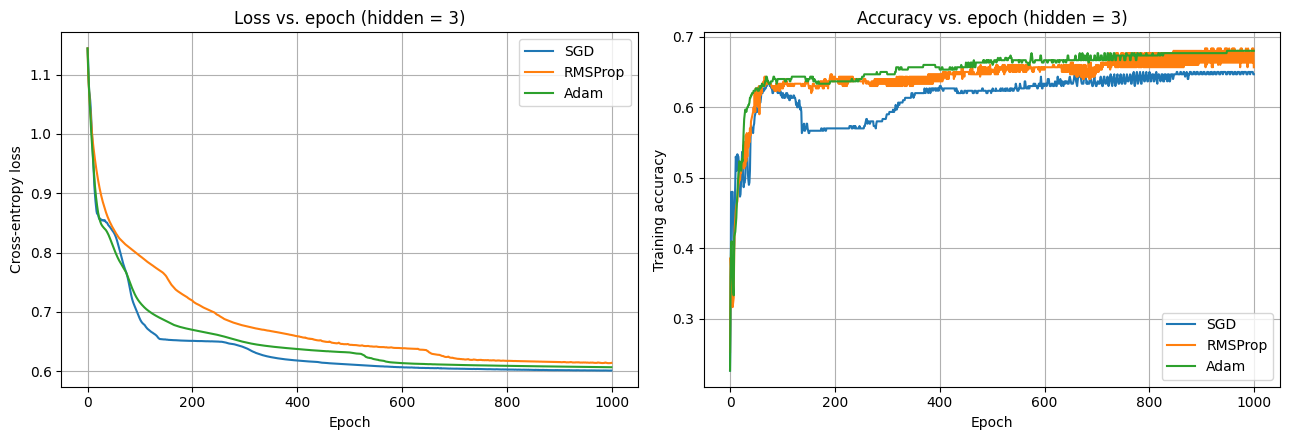

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, res in results_small.items():
    axes[0].plot(res["losses"], label=name)
    axes[1].plot(res["accs"], label=name)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_title("Loss vs. epoch (hidden = 3)"); axes[0].legend()
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Training accuracy")
axes[1].set_title("Accuracy vs. epoch (hidden = 3)"); axes[1].legend()
fig.tight_layout(); plt.show()

### 3(b) Optimizer summary

In [11]:
import pandas as pd
summary_small = pd.DataFrame({
    "Optimizer": list(results_small.keys()),
    "Learning rate": [0.5, 0.02, 0.05],
    "Final loss": [results_small[k]["losses"][-1] for k in results_small],
    "Final train acc": [results_small[k]["accs"][-1] for k in results_small],
    "Epochs to loss<0.9": [
        int(np.argmax(results_small[k]["losses"] < 0.9)) if np.any(results_small[k]["losses"] < 0.9)
        else -1 for k in results_small
    ],
})
print(summary_small.to_string(index=False))

Optimizer  Learning rate  Final loss  Final train acc  Epochs to loss<0.9
      SGD           0.50    0.601289         0.646667                  14
  RMSProp           0.02    0.614206         0.656667                  25
     Adam           0.05    0.606874         0.680000                  16


### 3(c) Decision boundary for the best optimizer

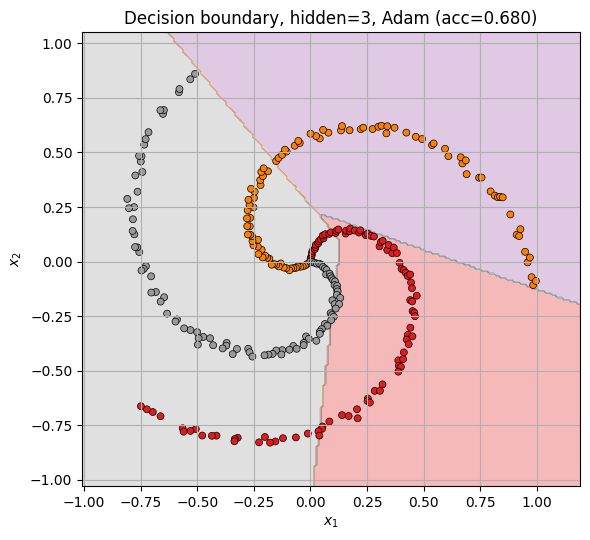

Best optimizer for the 3-neuron network: Adam


In [12]:
def plot_decision_boundary(net, X, y, title, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.5))
    h = 0.01
    x_min, x_max = X[:, 0].min() - 0.2, X[:, 0].max() + 0.2
    y_min, y_max = X[:, 1].min() - 0.2, X[:, 1].max() + 0.2
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = net.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=plt.cm.Set1, alpha=0.3)
    ax.scatter(X[:, 0], X[:, 1], c=y, s=25, cmap=plt.cm.Set1, edgecolors="k", linewidths=0.5)
    ax.set_title(title)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    return ax


best_small = max(results_small, key=lambda k: results_small[k]["accs"][-1])
plot_decision_boundary(results_small[best_small]["net"], X, y,
                        f"Decision boundary, hidden=3, {best_small} "
                        f"(acc={results_small[best_small]['accs'][-1]:.3f})")
plt.tight_layout(); plt.show()
print(f"Best optimizer for the 3-neuron network: {best_small}")

## Problem 4 — Network Capacity: A Bigger Hidden Layer

### 4(a) Prediction before running

The 3-neuron network is expected to underfit the nonlinear spiral dataset, while a wider hidden layer should provide substantially greater representational capacity.

### 4(b) Repeat with 64 hidden neurons

In [13]:
import time

optimizer_configs_big = {
    "SGD":     lambda: SGD(lr=0.5, momentum=0.9),
    "RMSProp": lambda: RMSProp(lr=0.02),
    "Adam":    lambda: Adam(lr=0.05),
}

results_big = {}
timings = {}
for name, make_opt in optimizer_configs_big.items():
    net = SimpleNet(n_in=2, n_hidden=64, n_out=3, seed=0)
    t0 = time.time()
    losses, accs = train(net, X, y, make_opt(), epochs=1000)
    elapsed = time.time() - t0
    results_big[name] = {"losses": losses, "accs": accs, "net": net}
    timings[name] = elapsed
    print(f"{name:8s}: final loss = {losses[-1]:.4f}, final training accuracy = {accs[-1]:.4f}, "
          f"time = {elapsed:.2f}s")

# also time the small network for the cost comparison in 4(c)
timings_small = {}
for name, make_opt in optimizer_configs_small.items():
    net_s = SimpleNet(n_in=2, n_hidden=3, n_out=3, seed=0)
    t0 = time.time()
    train(net_s, X, y, make_opt(), epochs=1000)
    timings_small[name] = time.time() - t0

SGD     : final loss = 0.0218, final training accuracy = 0.9933, time = 0.32s
RMSProp : final loss = 0.0118, final training accuracy = 0.9933, time = 0.32s
Adam    : final loss = 0.0123, final training accuracy = 0.9933, time = 0.34s


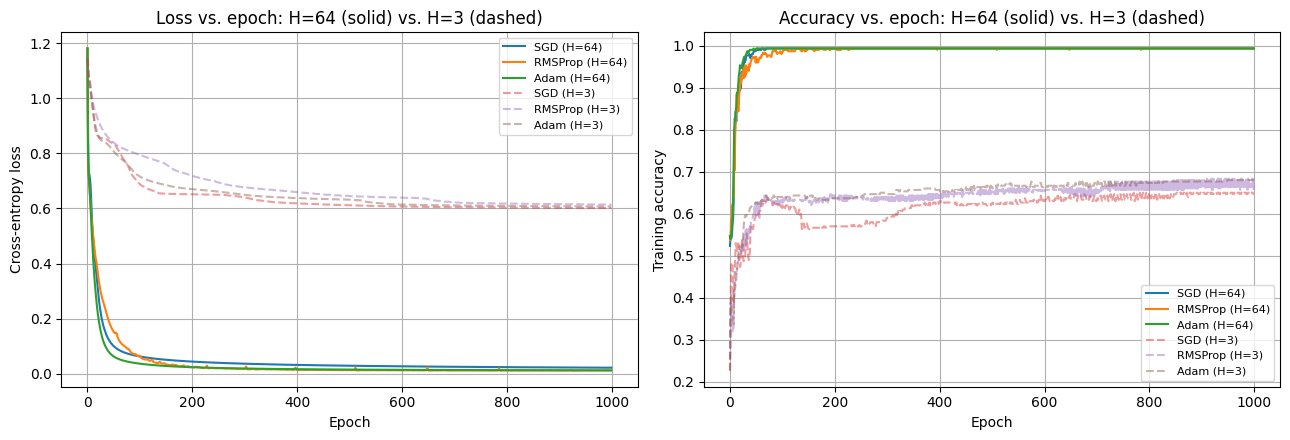

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, res in results_big.items():
    axes[0].plot(res["losses"], label=f"{name} (H=64)")
    axes[1].plot(res["accs"], label=f"{name} (H=64)")
for name, res in results_small.items():
    axes[0].plot(res["losses"], "--", alpha=0.45, label=f"{name} (H=3)")
    axes[1].plot(res["accs"], "--", alpha=0.45, label=f"{name} (H=3)")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_title("Loss vs. epoch: H=64 (solid) vs. H=3 (dashed)")
axes[0].legend(fontsize=8)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Training accuracy")
axes[1].set_title("Accuracy vs. epoch: H=64 (solid) vs. H=3 (dashed)")
axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

### 4(c) Compare the two network capacities

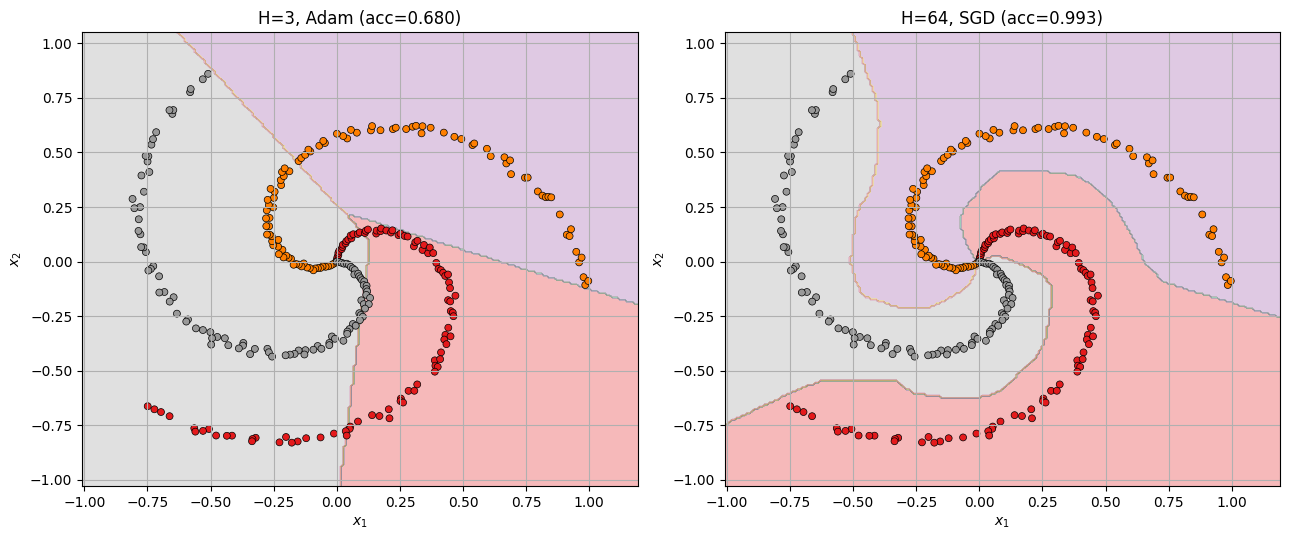

In [15]:
best_big = max(results_big, key=lambda k: results_big[k]["accs"][-1])
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_decision_boundary(results_small[best_small]["net"], X, y,
                        f"H=3, {best_small} (acc={results_small[best_small]['accs'][-1]:.3f})",
                        ax=axes[0])
plot_decision_boundary(results_big[best_big]["net"], X, y,
                        f"H=64, {best_big} (acc={results_big[best_big]['accs'][-1]:.3f})",
                        ax=axes[1])
fig.tight_layout(); plt.show()

In [ ]:
comparison = pd.DataFrame({
    "Optimizer": list(results_small.keys()),
    "Final acc (H=3)": [results_small[k]["accs"][-1] for k in results_small],
    "Final acc (H=64)": [results_big[k]["accs"][-1] for k in results_big],
    "Final loss (H=3)": [results_small[k]["losses"][-1] for k in results_small],
    "Final loss (H=64)": [results_big[k]["losses"][-1] for k in results_big],
    "Train time H=3 (s)": [timings_small[k] for k in results_small],
    "Train time H=64 (s)": [timings[k] for k in results_big],
})
print(comparison.to_string(index=False))

n_params_small = 2 * 3 + 3 + 3 * 3 + 3
n_params_big = 2 * 64 + 64 + 64 * 3 + 3
print(f"\nParameter count: H=3 -> {n_params_small}, H=64 -> {n_params_big} "
      f"({n_params_big / n_params_small:.1f}x more parameters)")

# Part B — MLP in PyTorch for Automatic Modulation Classification

## B0. Setup

PyTorch and scikit-learn are used for the AMC experiments.

In [ ]:
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(0)
np.random.seed(0)
print(f"PyTorch version: {torch.__version__}, device: CPU (no GPU required for this lab)")

## Problem 5 — Signal Visualization and Feature Engineering

### Dataset generation

The experiment uses five modulation classes:

- BPSK
- QPSK
- 8PSK
- 16QAM
- 64QAM

In [ ]:
MODULATIONS = ["BPSK", "QPSK", "8PSK", "16QAM", "64QAM"]


def make_symbols(mod, n, rng):
    """Draw n unit-average-power symbols from the given constellation."""
    if mod == "BPSK":
        return (2 * rng.integers(0, 2, n) - 1).astype(complex)
    if mod == "QPSK":
        return np.exp(1j * (np.pi / 4 + rng.integers(0, 4, n) * np.pi / 2))
    if mod == "8PSK":
        return np.exp(1j * (rng.integers(0, 8, n) * np.pi / 4))
    if mod == "16QAM":
        lv = np.array([-3, -1, 1, 3])
        return (rng.choice(lv, n) + 1j * rng.choice(lv, n)) / np.sqrt(10)
    if mod == "64QAM":
        lv = np.array([-7, -5, -3, -1, 1, 3, 5, 7])
        return (rng.choice(lv, n) + 1j * rng.choice(lv, n)) / np.sqrt(42)
    raise ValueError(mod)


def generate_amc_dataset(n_per_class_per_snr=100, n_symbols=128,
                          snrs=range(-10, 21, 2), seed=0):
    rng = np.random.default_rng(seed)
    X, y, snr_list = [], [], []
    for snr_db in snrs:
        for k, mod in enumerate(MODULATIONS):
            for _ in range(n_per_class_per_snr):
                s = make_symbols(mod, n_symbols, rng)
                s = s * np.exp(1j * rng.uniform(0, 2 * np.pi))     # unknown carrier phase
                sig_pow = np.mean(np.abs(s) ** 2)
                noise_pow = sig_pow / (10 ** (snr_db / 10))
                w = np.sqrt(noise_pow / 2) * (rng.normal(size=n_symbols)
                                               + 1j * rng.normal(size=n_symbols))
                r = s + w
                X.append(np.stack([r.real, r.imag]))               # (2, n_symbols): I and Q
                y.append(k)
                snr_list.append(snr_db)
    return np.array(X), np.array(y), np.array(snr_list)


t0 = time.time()
X_iq, y_mod, snr = generate_amc_dataset(n_per_class_per_snr=100, n_symbols=128, seed=0)
print(f"Generated {X_iq.shape[0]} signals of shape {X_iq.shape[1:]} in {time.time() - t0:.2f}s")
print(f"SNR values: {sorted(set(snr))} dB")
print(f"Class balance: {np.bincount(y_mod)} (per modulation)")

### 5(a) Constellation diagrams at high and low SNR

In [ ]:
fig, axes = plt.subplots(5, 2, figsize=(9, 20))
for k, mod in enumerate(MODULATIONS):
    for col, target_snr in enumerate([18, -4]):
        idx = np.where((y_mod == k) & (snr == target_snr))[0][0]
        iq = X_iq[idx]
        axes[k, col].scatter(iq[0], iq[1], s=6, alpha=0.6)
        axes[k, col].set_title(f"{mod}, SNR = {target_snr:+d} dB", fontsize=10)
        axes[k, col].set_xlabel("I"); axes[k, col].set_ylabel("Q")
        axes[k, col].set_aspect("equal", adjustable="datalim")
fig.tight_layout(); plt.show()

### 5(b) Why not feed raw I/Q directly into an MLP?

Raw I/Q samples are affected by unknown carrier phase and observation noise. Hand-crafted statistical features provide a more compact representation that is less sensitive to nuisance variation and captures modulation-dependent structure.

### 5(c) Feature extractor

Use amplitude/phase statistics and higher-order cumulants as the AMC feature vector.

In [ ]:
FEATURE_NAMES_AMC = [
    "std_amp", "mean_amp2", "std_amp2", "kurtosis_amp", "skew_amp",
    "abs_C20", "abs_C40", "abs_C42", "C40_norm", "C42_norm",
    "std_phase", "mean_abs_phase",
]


def extract_amc_features(X_iq_batch):
    """Compute AMC features for a batch of (2, n_symbols) I/Q signals."""
    feats = []
    for iq in X_iq_batch:
        r = iq[0] + 1j * iq[1]
        # Normalize to unit average power: makes features independent of received signal level,
        # which is essential since absolute power carries no modulation information.
        r = r / (np.sqrt(np.mean(np.abs(r) ** 2)) + 1e-12)
        a = np.abs(r)

        # Higher-order cumulants -- the classical statistical tool for AMC, because different
        # constellations have characteristically different 4th-order cumulants.
        C20 = np.mean(r ** 2)
        C21 = np.mean(np.abs(r) ** 2)
        C40 = np.mean(r ** 4) - 3 * C20 ** 2
        C42 = np.mean(np.abs(r) ** 4) - np.abs(C20) ** 2 - 2 * C21 ** 2

        a_m, a_s = np.mean(a), np.std(a) + 1e-12
        phase = np.angle(r)

        feats.append([
            np.std(a), np.mean(a ** 2), np.std(a ** 2),
            np.mean(((a - a_m) / a_s) ** 4),       # kurtosis of amplitude
            np.mean(((a - a_m) / a_s) ** 3),       # skewness of amplitude
            np.abs(C20), np.abs(C40), np.abs(C42),
            np.abs(C40) / (C21 ** 2 + 1e-12),
            np.abs(C42) / (C21 ** 2 + 1e-12),
            np.std(phase), np.mean(np.abs(phase)),
        ])
    return np.array(feats)


t0 = time.time()
F_amc = extract_amc_features(X_iq)
print(f"Feature matrix: {F_amc.shape} (N x d) in {time.time() - t0:.2f}s")
print(f"Contains NaN/inf? {np.any(~np.isfinite(F_amc))}")

In [ ]:
high_snr_mask = snr >= 14
feat_df_amc = pd.DataFrame(F_amc[high_snr_mask], columns=FEATURE_NAMES_AMC)
feat_df_amc["mod"] = [MODULATIONS[i] for i in y_mod[high_snr_mask]]

plot_feats = ["std_amp", "kurtosis_amp", "C40_norm", "C42_norm"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
for ax, feat in zip(axes, plot_feats):
    feat_df_amc.boxplot(column=feat, by="mod", ax=ax)
    ax.set_title(feat); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=45)
plt.suptitle("")
fig.tight_layout(); plt.show()

### 5(d) Stratified split and standardization

In [ ]:
# Stratify by the (modulation, SNR) pair so BOTH splits span the full SNR range -- otherwise the test
# set could accidentally over-represent easy high-SNR or hard low-SNR signals.
strat_key = np.array([f"{m}_{s}" for m, s in zip(y_mod, snr)])

idx_train, idx_test = train_test_split(
    np.arange(len(y_mod)), test_size=0.3, random_state=0, stratify=strat_key
)

X_amc_train, X_amc_test = F_amc[idx_train], F_amc[idx_test]
y_amc_train, y_amc_test = y_mod[idx_train], y_mod[idx_test]
snr_train, snr_test = snr[idx_train], snr[idx_test]

scaler_amc = StandardScaler().fit(X_amc_train)          # training statistics only
X_amc_train_s = scaler_amc.transform(X_amc_train)
X_amc_test_s = scaler_amc.transform(X_amc_test)

print(f"Train: {X_amc_train_s.shape}, Test: {X_amc_test_s.shape}")
print(f"Train SNR coverage: {sorted(set(snr_train))}")
print(f"Test  SNR coverage: {sorted(set(snr_test))}")

## Problem 6 — MLP Implementation in PyTorch

### 6(a) Model

Use two hidden layers with 128 units and ReLU activations.

In [ ]:
def make_mlp(n_in, n_hidden=128, n_out=5, seed=0):
    torch.manual_seed(seed)
    return nn.Sequential(
        nn.Linear(n_in, n_hidden),
        nn.ReLU(),
        nn.Linear(n_hidden, n_hidden),
        nn.ReLU(),
        nn.Linear(n_hidden, n_out),      # raw logits out -- CrossEntropyLoss applies softmax itself
    )


model_demo = make_mlp(X_amc_train_s.shape[1])
print(model_demo)
print(f"\nTotal parameters: {sum(p.numel() for p in model_demo.parameters())}")

### 6(b) Mapping PyTorch back to Part A

| PyTorch component | Part A equivalent | Purpose |
|---|---|---|
| `nn.Linear` | `DenseLayer` | Affine transformation |
| `nn.ReLU` | `ReLU` | Nonlinear activation |
| `CrossEntropyLoss` | `SoftmaxCrossEntropy` | Classification loss |
| PyTorch optimizer | NumPy optimizer classes | Parameter updates |

### 6(c) Training loop

In [ ]:
def train_torch(model, X_tr, y_tr, X_te, y_te, optimizer, epochs=300, batch_size=256, seed=0):
    """Full-batch-shuffled mini-batch training. Returns per-epoch loss and test accuracy."""
    torch.manual_seed(seed)
    loss_fn = nn.CrossEntropyLoss()
    Xt = torch.tensor(X_tr, dtype=torch.float32)
    yt = torch.tensor(y_tr, dtype=torch.long)
    Xv = torch.tensor(X_te, dtype=torch.float32)

    n = len(yt)
    losses, test_accs = [], []
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(n)
        epoch_loss = 0.0
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            optimizer.zero_grad()
            loss = loss_fn(model(Xt[idx]), yt[idx])
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(idx)
        losses.append(epoch_loss / n)

        model.eval()
        with torch.no_grad():
            pred = model(Xv).argmax(1).numpy()
        test_accs.append(accuracy_score(y_te, pred))
    return np.array(losses), np.array(test_accs)


model_main = make_mlp(X_amc_train_s.shape[1], seed=0)
opt_main = torch.optim.Adam(model_main.parameters(), lr=0.005)
t0 = time.time()
losses_main, accs_main = train_torch(model_main, X_amc_train_s, y_amc_train,
                                      X_amc_test_s, y_amc_test, opt_main, epochs=300)
print(f"Trained in {time.time() - t0:.1f}s. "
      f"Final loss = {losses_main[-1]:.4f}, final test accuracy = {accs_main[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(losses_main); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Training loss")
axes[0].set_title("PyTorch MLP (Adam): loss vs. epoch")
axes[1].plot(accs_main, color="tab:orange"); axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Test accuracy"); axes[1].set_title("Test accuracy vs. epoch")
fig.tight_layout(); plt.show()

## Problem 7 — Optimizer Comparison and Convergence Analysis

### 7(a) SGD vs. RMSProp vs. Adam

All optimizers use the same model initialization for a fair comparison.

In [ ]:
optimizer_builders = {
    "SGD (momentum=0.9)": lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9),
    "RMSProp":            lambda p: torch.optim.RMSprop(p, lr=0.005),
    "Adam":               lambda p: torch.optim.Adam(p, lr=0.005),
}

results_amc = {}
for name, build in optimizer_builders.items():
    model = make_mlp(X_amc_train_s.shape[1], seed=0)     # identical init across optimizers
    t0 = time.time()
    losses, accs = train_torch(model, X_amc_train_s, y_amc_train,
                                X_amc_test_s, y_amc_test, build(model.parameters()),
                                epochs=300, seed=0)
    results_amc[name] = {"losses": losses, "accs": accs, "model": model,
                          "time": time.time() - t0}
    print(f"{name:20s}: final loss = {losses[-1]:.4f}, "
          f"final test acc = {accs[-1]:.4f}, time = {results_amc[name]['time']:.1f}s")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, res in results_amc.items():
    axes[0].plot(res["losses"], label=name)
    axes[1].plot(res["accs"], label=name)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Training loss")
axes[0].set_title("AMC: loss vs. epoch by optimizer"); axes[0].legend()
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Test accuracy")
axes[1].set_title("AMC: test accuracy vs. epoch by optimizer"); axes[1].legend()
fig.tight_layout(); plt.show()

summary_amc = pd.DataFrame({
    "Optimizer": list(results_amc.keys()),
    "Final loss": [results_amc[k]["losses"][-1] for k in results_amc],
    "Final test acc": [results_amc[k]["accs"][-1] for k in results_amc],
    "Best test acc": [results_amc[k]["accs"].max() for k in results_amc],
    "Train time (s)": [results_amc[k]["time"] for k in results_amc],
})
print(summary_amc.to_string(index=False))

### 7(b) Learning-rate sweep using Adam

In [ ]:
lr_values = [1e-4, 1e-3, 1e-2, 1e-1]
lr_results = {}
for lr in lr_values:
    model = make_mlp(X_amc_train_s.shape[1], seed=0)
    losses, accs = train_torch(model, X_amc_train_s, y_amc_train,
                                X_amc_test_s, y_amc_test,
                                torch.optim.Adam(model.parameters(), lr=lr),
                                epochs=200, seed=0)
    lr_results[lr] = {"losses": losses, "accs": accs}
    print(f"lr = {lr:<8g}: final loss = {losses[-1]:.4f}, final test acc = {accs[-1]:.4f}")

plt.figure(figsize=(7.5, 4.5))
for lr, res in lr_results.items():
    plt.plot(res["losses"], label=f"lr = {lr:g}")
plt.xlabel("Epoch"); plt.ylabel("Training loss")
plt.title("Adam: learning-rate sweep")
plt.legend(); plt.tight_layout(); plt.show()

### 7(c) Discussion of convergence characteristics

Compare convergence speed, final loss, stability, and test accuracy across the optimizers and learning rates.

## Problem 8 — Performance vs. SNR and Error Analysis

### 8(a) Accuracy versus SNR

In [ ]:
best_opt_name = max(results_amc, key=lambda k: results_amc[k]["accs"].max())
best_model_amc = results_amc[best_opt_name]["model"]
print(f"Best optimizer by peak test accuracy: {best_opt_name}")

with torch.no_grad():
    pred_test_amc = best_model_amc(
        torch.tensor(X_amc_test_s, dtype=torch.float32)).argmax(1).numpy()

snr_levels = np.array(sorted(set(snr_test)))
acc_by_snr = np.array([
    accuracy_score(y_amc_test[snr_test == s], pred_test_amc[snr_test == s]) for s in snr_levels
])

chance = 1.0 / len(MODULATIONS)

plt.figure(figsize=(8, 5))
plt.plot(snr_levels, acc_by_snr, "o-", linewidth=2, label=f"MLP ({best_opt_name})")
plt.axhline(chance, color="red", linestyle="--",
            label=f"Chance = 1/{len(MODULATIONS)} = {chance:.2f}")
plt.xlabel("SNR (dB)"); plt.ylabel("Classification accuracy")
plt.title("AMC: classification accuracy vs. SNR")
plt.ylim(0, 1); plt.legend(); plt.tight_layout(); plt.show()

for s, a in zip(snr_levels, acc_by_snr):
    print(f"  SNR {s:+3d} dB: accuracy = {a:.3f}")

### 8(b) Confusion matrices at low and high SNR

In [ ]:
low_mask = snr_test <= 0
high_mask = snr_test >= 10

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, mask, label in zip(axes, [low_mask, high_mask],
                            ["Low SNR (<= 0 dB)", "High SNR (>= +10 dB)"]):
    cm = confusion_matrix(y_amc_test[mask], pred_test_amc[mask],
                          labels=range(len(MODULATIONS)))
    ConfusionMatrixDisplay(cm, display_labels=MODULATIONS).plot(
        ax=ax, colorbar=False, cmap="Blues", xticks_rotation=45)
    acc = accuracy_score(y_amc_test[mask], pred_test_amc[mask])
    ax.set_title(f"{label} -- accuracy {acc:.3f}")
fig.tight_layout(); plt.show()

# identify the dominant high-SNR confusion automatically
cm_high = confusion_matrix(y_amc_test[high_mask], pred_test_amc[high_mask],
                           labels=range(len(MODULATIONS)))
cm_off = cm_high.copy()
np.fill_diagonal(cm_off, 0)
i_true, i_pred = np.unravel_index(np.argmax(cm_off), cm_off.shape)
print(f"Dominant high-SNR confusion: true {MODULATIONS[i_true]} "
      f"predicted as {MODULATIONS[i_pred]} ({cm_off[i_true, i_pred]} times)")
print("\nHigh-SNR per-class recall:")
for k, mod in enumerate(MODULATIONS):
    recall = cm_high[k, k] / cm_high[k].sum() if cm_high[k].sum() else float("nan")
    print(f"  {mod:6s}: {recall:.3f}")

### 8(c) Proposed change

**Hypothesis:** the dominant 16QAM/64QAM confusion is limited by estimation variance in higher-order cumulants. A longer observation window should provide more samples for feature estimation and may improve discrimination.

### 8(d) Bonus — test the hypothesis

In [ ]:
t0 = time.time()
X_iq_long, y_mod_long, snr_long = generate_amc_dataset(
    n_per_class_per_snr=100, n_symbols=512, seed=0)      # 4x longer observation window
F_long = extract_amc_features(X_iq_long)
print(f"Regenerated with n_symbols=512 and re-extracted features in {time.time() - t0:.1f}s")

strat_key_long = np.array([f"{m}_{s}" for m, s in zip(y_mod_long, snr_long)])
idx_tr_l, idx_te_l = train_test_split(np.arange(len(y_mod_long)), test_size=0.3,
                                       random_state=0, stratify=strat_key_long)

scaler_long = StandardScaler().fit(F_long[idx_tr_l])
Xl_tr = scaler_long.transform(F_long[idx_tr_l])
Xl_te = scaler_long.transform(F_long[idx_te_l])
yl_tr, yl_te = y_mod_long[idx_tr_l], y_mod_long[idx_te_l]
snr_te_l = snr_long[idx_te_l]

model_long = make_mlp(Xl_tr.shape[1], seed=0)
best_builder = optimizer_builders[best_opt_name]
losses_l, accs_l = train_torch(model_long, Xl_tr, yl_tr, Xl_te, yl_te,
                                best_builder(model_long.parameters()), epochs=300, seed=0)
print(f"n_symbols=512: final test accuracy = {accs_l[-1]:.4f} "
      f"(peak {accs_l.max():.4f})")
print(f"n_symbols=128: final test accuracy = {results_amc[best_opt_name]['accs'][-1]:.4f} "
      f"(peak {results_amc[best_opt_name]['accs'].max():.4f})")

In [ ]:
with torch.no_grad():
    pred_long = model_long(torch.tensor(Xl_te, dtype=torch.float32)).argmax(1).numpy()

acc_by_snr_long = np.array([
    accuracy_score(yl_te[snr_te_l == s], pred_long[snr_te_l == s]) for s in snr_levels
])

plt.figure(figsize=(8, 5))
plt.plot(snr_levels, acc_by_snr, "o-", label="n_symbols = 128 (original)")
plt.plot(snr_levels, acc_by_snr_long, "s-", label="n_symbols = 512 (proposed change)")
plt.axhline(chance, color="red", linestyle="--", label=f"Chance = {chance:.2f}")
plt.xlabel("SNR (dB)"); plt.ylabel("Classification accuracy")
plt.title("Effect of a longer observation window on accuracy vs. SNR")
plt.ylim(0, 1); plt.legend(); plt.tight_layout(); plt.show()

improvement = acc_by_snr_long - acc_by_snr
print("Per-SNR improvement (512-symbol minus 128-symbol):")
for s, base, new, d in zip(snr_levels, acc_by_snr, acc_by_snr_long, improvement):
    print(f"  SNR {s:+3d} dB: {base:.3f} -> {new:.3f}  ({d:+.3f})")
print(f"\nMean improvement across all SNRs: {improvement.mean():+.4f}")
print(f"Mean improvement at SNR >= +10 dB : {improvement[snr_levels >= 10].mean():+.4f}")
print(f"Mean improvement at SNR <= -6 dB  : {improvement[snr_levels <= -6].mean():+.4f}")

In [ ]:
cm_high_long = confusion_matrix(yl_te[snr_te_l >= 10], pred_long[snr_te_l >= 10],
                                 labels=range(len(MODULATIONS)))
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, cm, label in zip(axes, [cm_high, cm_high_long],
                          ["n_symbols=128 (original)", "n_symbols=512 (proposed)"]):
    ConfusionMatrixDisplay(cm, display_labels=MODULATIONS).plot(
        ax=ax, colorbar=False, cmap="Blues", xticks_rotation=45)
    ax.set_title(f"High-SNR confusion, {label}")
fig.tight_layout(); plt.show()

qam_conf_before = cm_high[3, 4] + cm_high[4, 3]
qam_conf_after = cm_high_long[3, 4] + cm_high_long[4, 3]
print(f"16QAM<->64QAM confusions at high SNR: {qam_conf_before} (128 symbols) "
      f"-> {qam_conf_after} (512 symbols)")

# Summary

| Problem | Main task |
|---|---|
| A1 | Spiral dataset generation and linear-separability discussion |
| A2 | Neural-network components, optimizers, and gradient verification |
| A3 | Training and optimizer comparison |
| A4 | Hidden-layer capacity comparison |
| B5 | AMC signal generation and feature engineering |
| B6 | PyTorch MLP implementation and training |
| B7 | Optimizer and learning-rate analysis |
| B8 | SNR performance, confusion matrices, and a longer-window experiment |